# Plotting a protein from its own analyses with `Protein.visualize`

[protein_viz_1](protein_viz_1.ipynb) builds a figure by hand, one track at a time, with `sparrow.visualize.proteinvis`. That gives complete control, but most of the time what we want is simpler: take a protein, pick some of the things sparrow can compute along its length, add the things we already know about it (domains, mutations, some per-residue signal from an experiment), and draw it. That's what `Protein.visualize` does.

Every `Protein` has a `.visualize` attribute with four methods:

* **`show_protein(...)`** draws the protein and returns the matplotlib figure and the axes of each track;
* **`save_protein(path, ...)`** takes the same arguments, draws the figure, saves it with the text editable in Illustrator, and closes it;
* **`visual_protein(...)`** builds the tracks without drawing them, so we can add to them, or plot the protein beside others;
* **`available_analyses()`** lists the analyses sparrow knows how to label.

The analyses are named exactly as `sparrow.batch` names them, so anything that works there works here. Positions always count from 1, and a region from `start` to `end` includes both ends.

The examples below go from a one-liner to figures with several proteins. Each section is independent once the first two cells have run.

In [1]:
import numpy as np

from sparrow import Protein
from sparrow.sparrow_exceptions import SparrowException
from sparrow.visualize.proteinvis import (
    Domain,
    GridTrack,
    Highlight,
    LinearTrack,
    Site,
    SiteTrack,
    plot_proteins,
    save_figure,
)

In [2]:
# the proteins we use throughout
# yeast Med15 (Gal11)
med15_seq = 'MSAAPVQDKDTLSNAERAKNVNGLLQVLMDINTLNGGSSDTADKIRIHAKNFEAALFAKSSSKKEYMDSMNEKVAVMRNTYNTRKNAVTAAAANNNIKPVEQHHINNLKNSGNSANNMNVNMNLNPQMFLNQQAQARQQVAQQLRNQQQQQQQQQQQQRRQLTPQQQQLVNQMKVAPIPKQLLQRIPNIPPNINTWQQVTALAQQKLLTPQDMEAAKEVYKIHQQLLFKARLQQQQAQAQAQANNNNNGLPQNGNINNNINIPQQQQMQPPNSSANNNPLQQQSSQNTVPNVLNQINQIFSPEEQRSLLQEAIETCKNFEKTQLGSTMTEPVKQSFIRKYINQKALRKIQALRDVKNNNNANNNGSNLQRAQNVPMNIIQQQQQQNTNNNDTIATSATPNAAAFSQQQNASSKLYQMQQQQQAQAQAQAQAQAQAQAQAQAQAAQAAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAHAQHQPSQQPQQAQQQPNPLHGLTPTAKDVEVIKQLSLDASKTNLRLTDVTNSLSNEEKEKIKMKLKQGQKLFVQVSNFAPQVYIITKNENFLKEVFQLRIFVKEILEKCAEGIFVVKLDTVDRLIIKYQKYWESMRIQILRRQAILRQQQQMANNNGNPGTTSTGNNNNIATQQNMQQSLQQMQHLQQLKMQQQQQQQQQQQQQQQQQQQQQQQHIYPSSTPGVANYSAMANAPGNNIPYMNHKNTSSMDFLNSMENTPKVPVSAAATPSLNKTINGKVNGRTKSNTIPVTSIPSTNKKLSISNAASQQPTPRSASNTAKSTPNTNPSPLKTQTKNGTPNPNNMKTVQSPMGAQPSYNSAIIENAFRKEELLLKDLEIRKLEISSRFKHRQEIFKDSPMDLFMSTLGDCLGIKDEEMLTSCTIPKAVVDHINGSGKRKPTKAAQRARDQDSIDISIKDNKLVMKSKFNKSNRSYSIALSNVAAIFKGIGGNFKDLSTLVHSSSPSTSSNMDVGNPRKRKASVLEISPQDSIASVLSPDSNIMSDSKKIKVDSPDDPFMTKSGATTSEKQEVTNEAPFLTSGTSSEQFNVWDWNNWTSAT'

# human hnRNPA1
hnrnpa1_seq = 'MSKSESPKEPEQLRKLFIGGLSFETTDESLRSHFEQWGTLTDCVVMRDPNTKRSRGFGFVTYATVEEVDAAMNARPHKVDGRVVEPKRAVSREDSQRPGAHLTVKKIFVGGIKEDTEEHHLRDYFEQYGKIEVIEIMTDRGSGKKRGFAFVTFDDHDSVDKIVIQKYHTVNGHNCEVRKALSKQEMASASSSQRGRSGSGNFGGGRGGGFGGNDNFGRGGNFSGRGGFGGSRGGGGYGGSGDGYNGFGNDGGYGGGGPGYSGGSRGYGSGGQGYGNQGSGYGGSGSYDSYNNGGGGGFGGGSGSNFGGGGSYNDFGNYNNQSSNFGPMKGGNFGGRSSGPYGGGGQYFAKPRNQGGYGGSSSSSSYGSGRRF'

# yeast Sup35
sup35_seq = 'MSDSNQGNNQQNYQQYSQNGNQQQGNNRYQGYQAYNAQAQPAGGYYQNYQGYSGYQQGGYQQYNPDAGYQQQYNPQGGYQQYNPQGGYQQQFNPQGGRGNYKNFNYNNNLQGYQAGFQPQSQGMSLNDFQKQQKQAAPKPKKTLKLVSSSGIKLANATKKVGTKPAESDKKEEEKSAETKEPTKEPTKVEEPVKKEEKPVQTEEKTEEKSELPKVEDLKISESTHNTNNANVTSADALIKEQEEEVDDEVVNDMFGGKDHVSLIFMGHVDAGKSTMGGNLLYLTGSVDKRTIEKYEREAKDAGRQGWYLSWVMDTNKEERNDGKTIEVGKAYFETEKRRYTILDAPGHKMYVSEMIGGASQADVGVLVISARKGEYETGFERGGQTREHALLAKTQGVNKMVVVVNKMDDPTVNWSKERYDQCVSNVSNFLRAIGYNIKTDVVFMPVSGYSGANLKDHVDPKECPWYTGPTLLEYLDTMNHVDRHINAPFMLPIAAKMKDLGTIVEGKIESGHIKKGQSTLLMPNKTAVEIQNIYNETENEVDMAMCGEQVKLRIKGVEEEDISPGFVLTSPKNPIKSVTKFVAQIAIVELKSIIAAGFSCVMHVHTAIEEVHIVKLLHKLEKGTNRKSKKPPAFAKKGMKVIAVLETEAPVCVETYQDYPQLGRFTLRDQGTTIAIGKIVKIAE'

# yeast Pab1
pab1_seq = 'MADITDKTAEQLENLNIQDDQKQAATGSESQSVENSSASLYVGDLEPSVSEAHLYDIFSPIGSVSSIRVCRDAITKTSLGYAYVNFNDHEAGRKAIEQLNYTPIKGRLCRIMWSQRDPSLRKKGSGNIFIKNLHPDIDNKALYDTFSVFGDILSSKIATDENGKSKGFGFVHFEEEGAAKEAIDALNGMLLNGQEIYVAPHLSRKERDSQLEETKAHYTNLYVKNINSETTDEQFQELFAKFGPIVSASLEKDADGKLKGFGFVNYEKHEDAVKAVEALNDSELNGEKLYVGRAQKKNERMHVLKKQYEAYRLEKMAKYQGVNLFVKNLDDSVDDEKLEEEFAPYGTITSAKVMRTENGKSKGFGFVCFSTPEEATKAITEKNQQIVAGKPLYVAIAQRKDVRRSQLAQQIQARNQMRYQQATAAAAAAAAGMPGQFMPPMFYGVMPPRGVPFNGPNPQQMNPMGGMPKNGMPPQFRNGPVYGVPPQGGFPRNANDNNQFYQQKQRQALGEQLYKKVSAKTSNEEAAGKITGMILDLPPQEVFPLLESDELFEQHYKEASAAYESFKKEQEQQTEQA'

# the SARS-CoV-2 nucleocapsid (N) protein
n_seq = 'MSDNGPQNQRNAPRITFGGPSDSTGSNQNGERSGARSKQRRPQGLPNNTASWFTALTQHGKEDLKFPRGQGVPINTNSSPDDQIGYYRRATRRIRGGDGKMKDLSPRWYFYYLGTGPEAGLPYGANKDGIIWVATEGALNTPKDHIGTRNPANNAAIVLQLPQGTTLPKGFYAEGSRGGSQASSRSSSRSRNSSRNSTPGSSRGTSPARMAGNGGDAALALLLLDRLNQLESKMSGKGQQQQGQTVTKKSAAEASKKPRQKRTATKAYNVTQAFGRRGPEQTQGNFGDQELIRQGTDYKHWPQIAQFAPSASAFFGMSRIGMEVTPSGTWLTYTGAIKLDDKDPNFKDQVILLNKHIDAYKTFPPTEPKKDKKKKADETQALPQRQKKQQTVTLLPAADLDDFSKQLQQSMSSADSTQA'

med15 = Protein(med15_seq)
hnrnpa1 = Protein(hnrnpa1_seq)
sup35 = Protein(sup35_seq)
pab1 = Protein(pab1_seq)
n_protein = Protein(n_seq)

## 1. The simplest plot

Name one analysis and we get one track. `show_protein` returns the figure and the axes of each track, so assign them (otherwise the notebook prints the tuple under the figure).

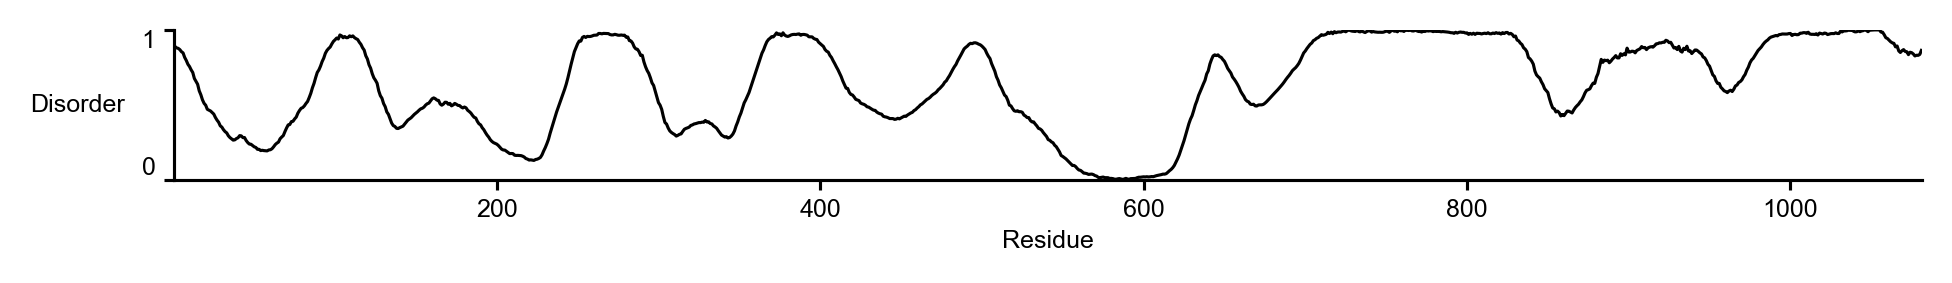

In [3]:
figure, axes = med15.visualize.show_protein("predictor.disorder")

Each analysis is computed by the protein and cached, exactly as if we'd called `med15.predictor.disorder()` ourselves, so drawing it again, or drawing something we've already computed, costs nothing.

## 2. What can we draw?

`available_analyses()` lists the analyses sparrow knows how to label and scale. Any other analysis that gives one value per residue can be drawn too; its track is just labelled with its name.

In [4]:
med15.visualize.available_analyses()

['predictor.disorder',
 'predictor.binary_disorder',
 'predictor.disorder_domains',
 'predictor.pLDDT',
 'predictor.dssp_helicity',
 'predictor.dssp_extended',
 'predictor.dssp_coil',
 'predictor.transmembrane_regions',
 'predictor.mitochondrial_targeting_sequence',
 'predictor.nuclear_export_signal',
 'predictor.nuclear_import_signal',
 'predictor.transactivation_domains',
 'predictor.pscore',
 'predictor.serine_phosphorylation',
 'predictor.threonine_phosphorylation',
 'predictor.tyrosine_phosphorylation',
 'linear_sequence_profile',
 'linear_composition_profile',
 'linear_property_profile',
 'low_complexity_mask',
 'low_complexity_domains',
 'plaac_prion_like_domains']

## 3. Several analyses at once

A list of names gives one track for each, top to bottom, in the order given.

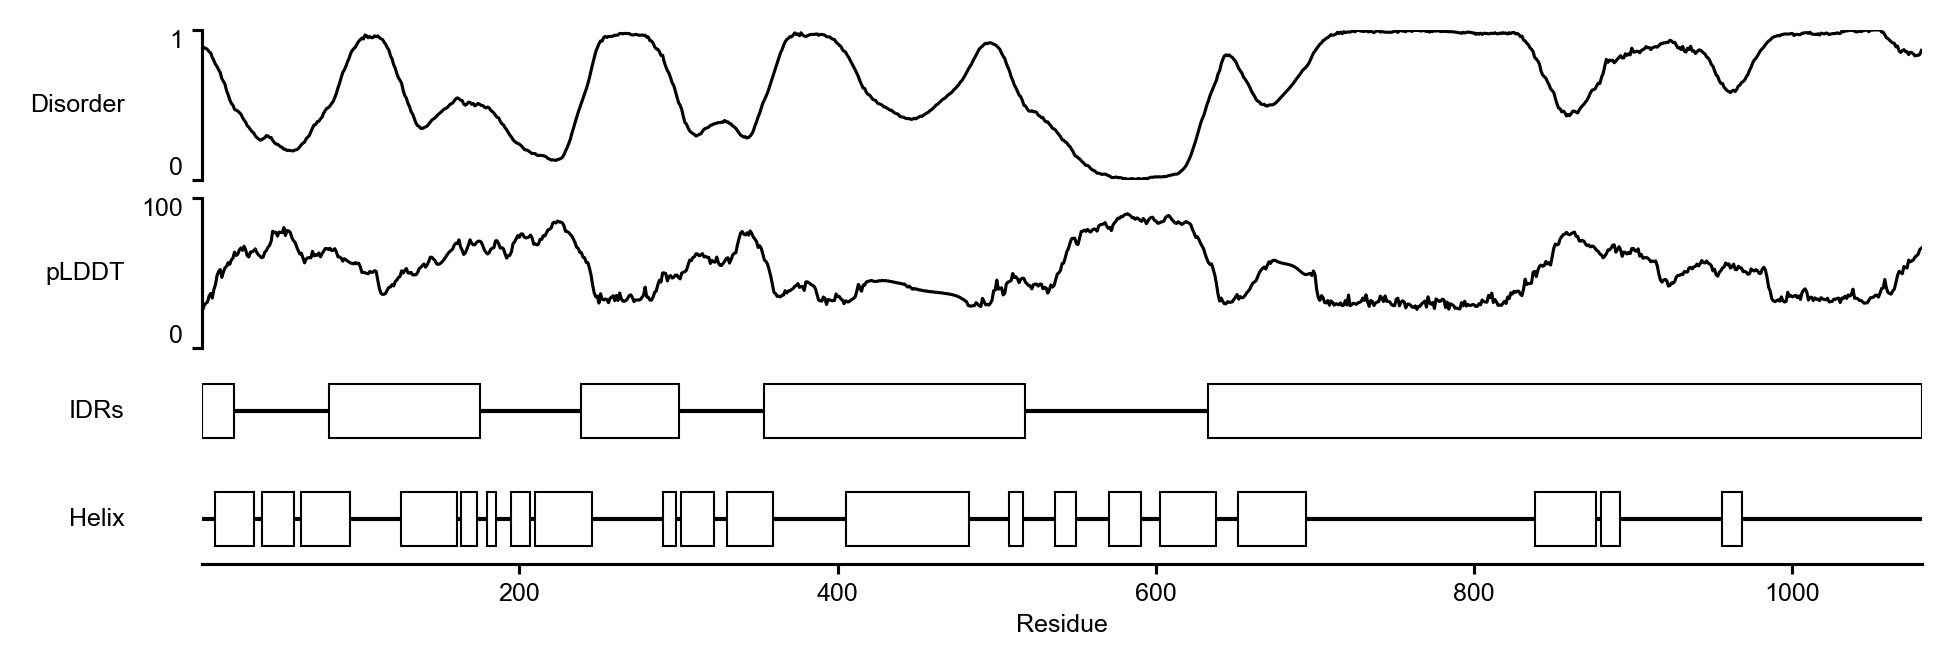

In [5]:
figure, axes = med15.visualize.show_protein(
    [
        "predictor.disorder",
        "predictor.pLDDT",
        "predictor.binary_disorder",
        "predictor.dssp_helicity",
    ]
)

## 4. Passing arguments

A name on its own is computed with its defaults. To pass arguments, pair the name with a dict of them, again just as `sparrow.batch` does. A list can mix bare names and dicts, and can hold the same analysis more than once with different arguments, such as two composition profiles below.

The linear profiles are labelled by what they profile, so `mode='NCPR'` gives a track labelled NCPR, and a composition profile is labelled with its residues.

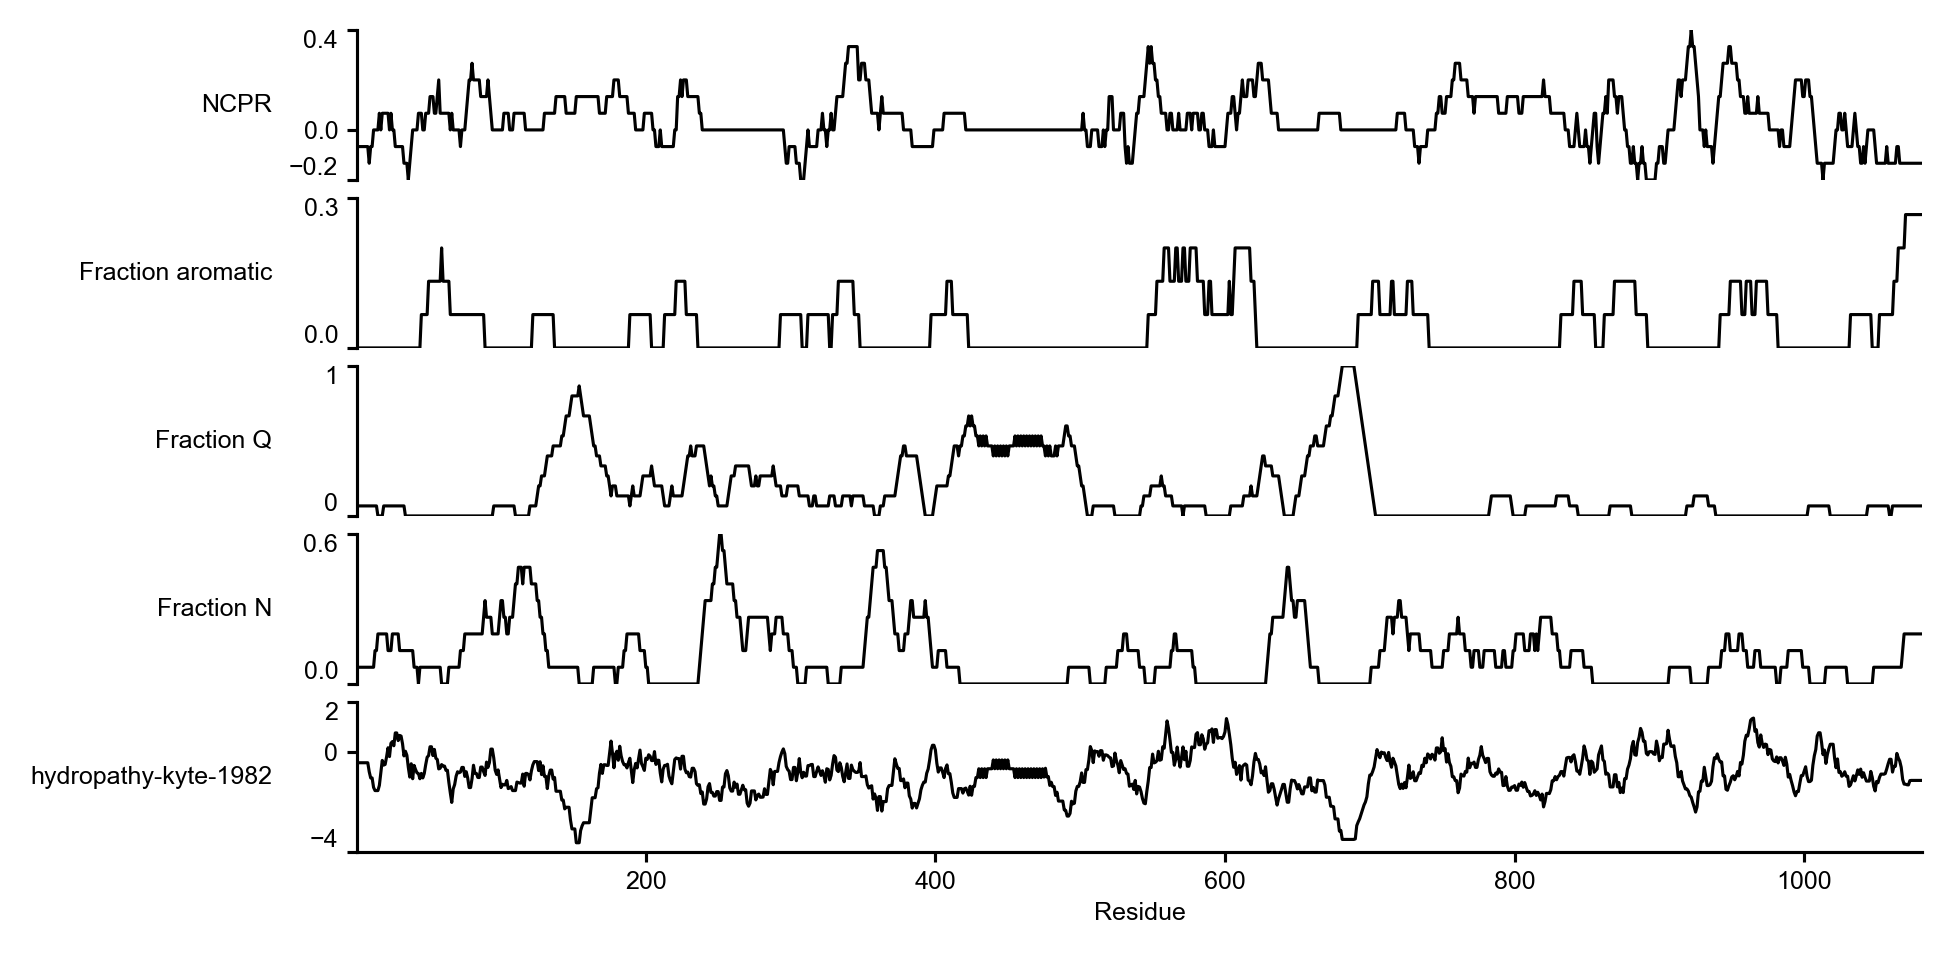

In [6]:
figure, axes = med15.visualize.show_protein(
    [
        {"linear_sequence_profile": {"mode": "NCPR", "window_size": 15}},
        {"linear_sequence_profile": {"mode": "aromatic", "window_size": 15}},
        {"linear_composition_profile": {"composition_list": ["Q"], "window_size": 15}},
        {"linear_composition_profile": {"composition_list": ["N"], "window_size": 15}},
        {"linear_property_profile": {"mode": "hydropathy-kyte-1982", "window_size": 15}},
    ]
)

One dict can also hold several analyses with their arguments. Here the DSSP predictors give a probability for each residue, rather than their default 1 or 0, so they're drawn as lines.

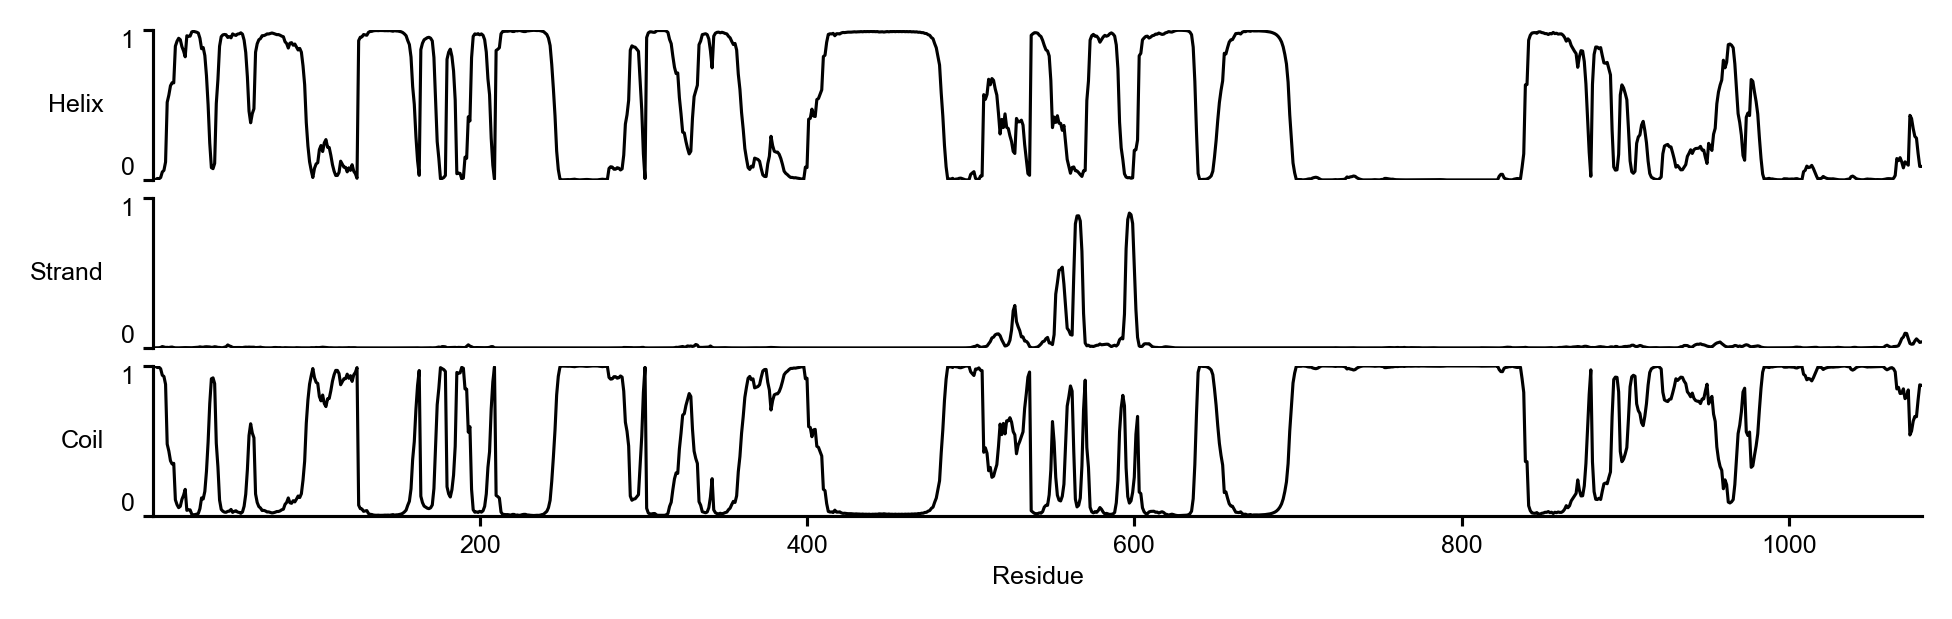

In [7]:
figure, axes = med15.visualize.show_protein(
    {
        "predictor.dssp_helicity": {"mode": "probability"},
        "predictor.dssp_extended": {"mode": "probability"},
        "predictor.dssp_coil": {"mode": "probability"},
    }
)

## 5. How each result becomes a track

How a track is drawn follows from what the analysis returns:

* **a value for each residue** (disorder, pLDDT, a linear profile) is a line on a y-axis of its own;
* **a 1 or 0 for each residue** (binary disorder, the DSSP classes, the low-complexity mask) is a box over each run of 1s;
* **a list of regions** (low-complexity domains, prion-like domains) is a box over each region;
* **the 1s of a phosphorylation predictor** are each marked as a site, and with `raw_values=True` we get the probability as a line instead.

Sup35 has a bit of everything: a disordered, Q/N-rich, prion-like N-terminal region, and a folded C-terminal domain. The two tyrosine phosphorylation tracks are both labelled pY, since they're the same predictor.

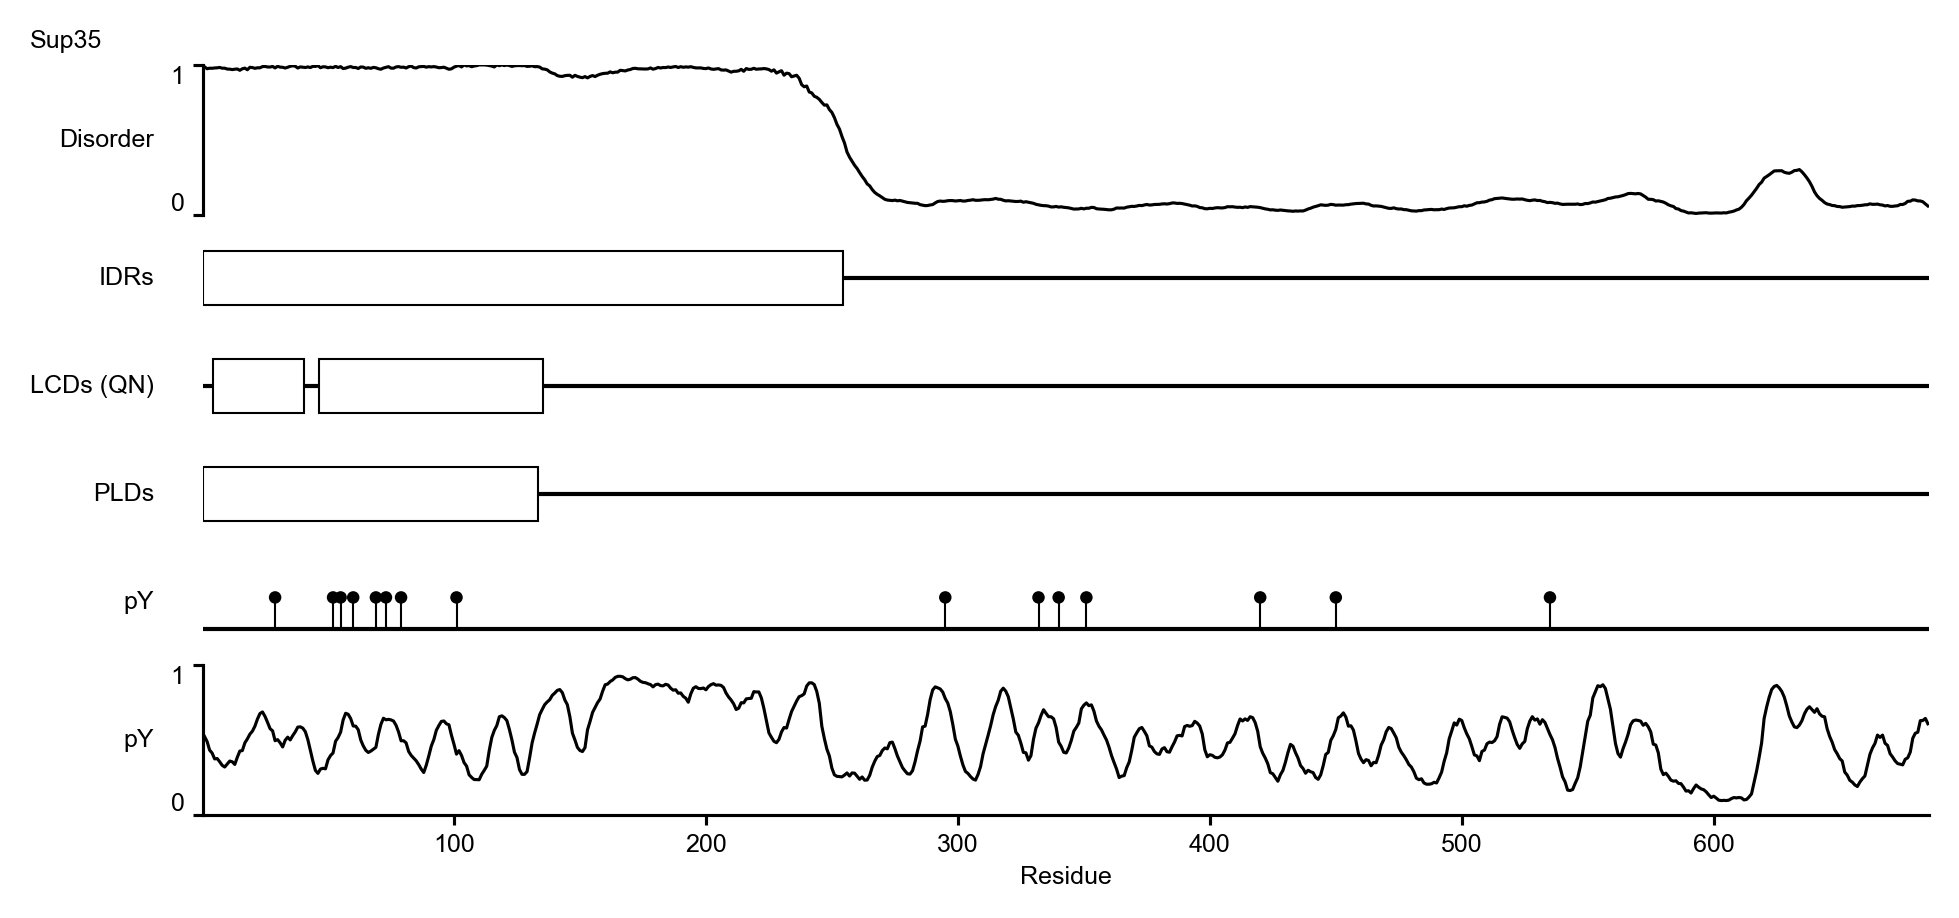

In [8]:
figure, axes = sup35.visualize.show_protein(
    [
        "predictor.disorder",                                           # a value per residue: a line
        "predictor.binary_disorder",                                    # 1 or 0 per residue: boxes
        {"low_complexity_domains": {"residue_selector": "QN"}},         # regions: boxes
        "plaac_prion_like_domains",                                     # regions: boxes
        "predictor.tyrosine_phosphorylation",                           # predicted sites: marks
        {"predictor.tyrosine_phosphorylation": {"raw_values": True}},   # or their probability: a line
    ],
    name="Sup35",
)

The same information often comes in more than one form, and each is drawn the way that suits it. The low-complexity mask and the low-complexity domains mark the same regions, one as 1s and 0s, the other as a list. `predictor.disorder_domains` gives 1 or 0 for each residue by default, and the IDRs' boundaries with `return_boundaries=True`. The regions metapredict and the low-complexity analyses return count from 0 and leave out their end; `visualize` converts them for us, so every track lines up.

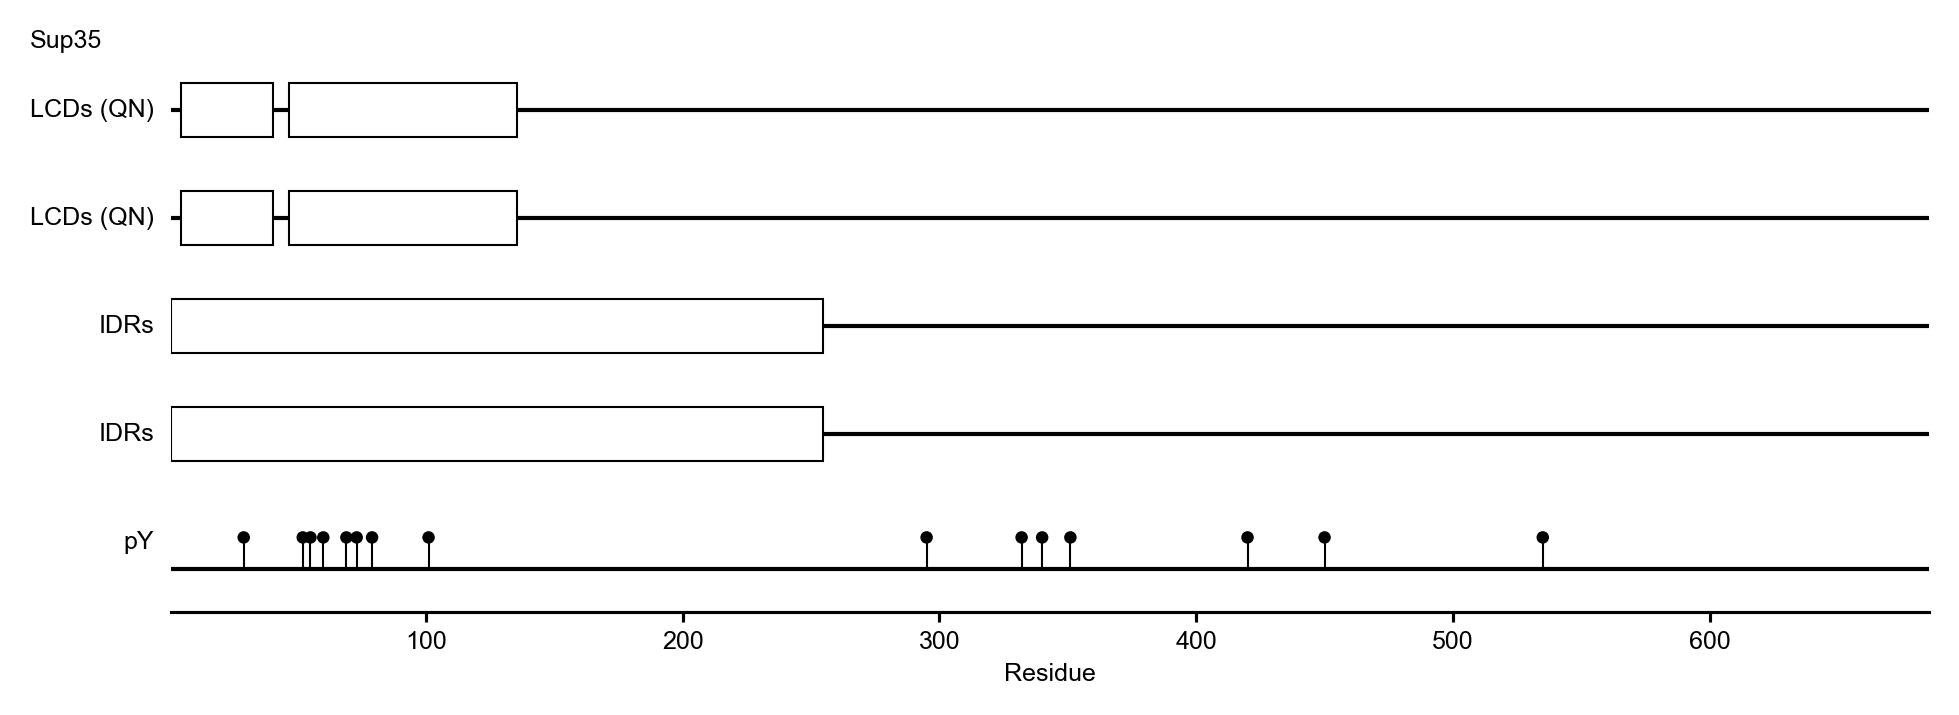

In [9]:
figure, axes = sup35.visualize.show_protein(
    [
        {"low_complexity_mask": {"residue_selector": "QN"}},
        {"low_complexity_domains": {"residue_selector": "QN"}},
        "predictor.disorder_domains",
        {"predictor.disorder_domains": {"return_boundaries": True}},
        {"predictor.tyrosine_phosphorylation": {"return_sites_only": True}},
    ],
    name="Sup35",
)

## 6. Our own per-residue signals

Values of our own go in `signals`, as a dict of each track's label and its values, one for each residue. Each is drawn as a line. A residue with no value can be NaN, and the line breaks there, which is handy for data that only covers part of the protein.

The two signals here are made up, standing in for something like a conservation score, or a signal measured only for a construct of residues 1 to 345.

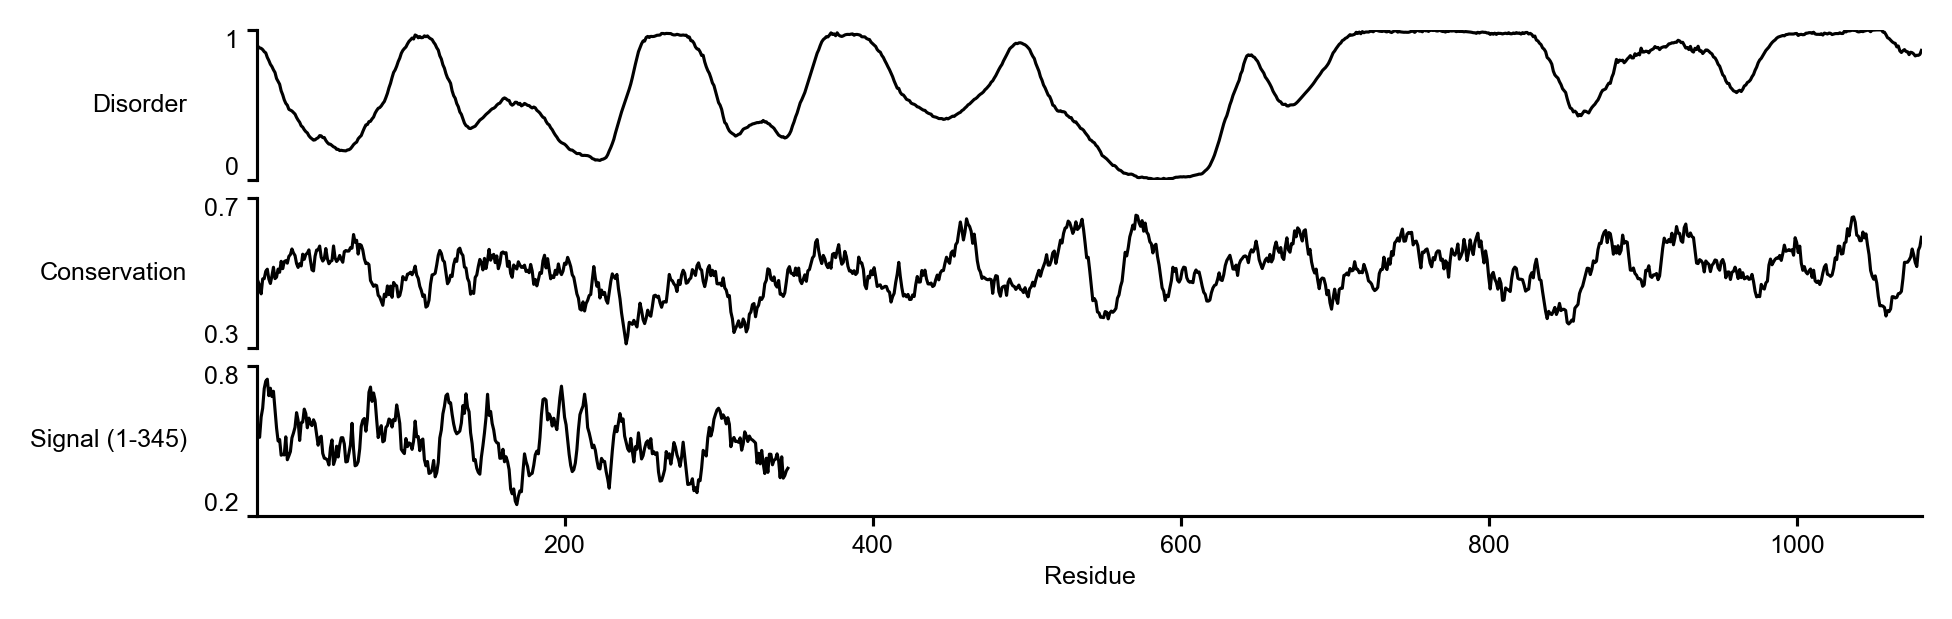

In [10]:
def smoothed_noise(n_residues, window_size, rng):
    """Made-up values from 0 to 1, one for each of n_residues: random numbers averaged over a sliding window."""
    noise = rng.random(n_residues + window_size - 1)
    return np.convolve(noise, np.ones(window_size) / window_size, mode="valid")


# a seed, so the made-up values are the same every time
rng = np.random.default_rng(seed=1)
conservation = smoothed_noise(len(med15_seq), 21, rng)

# a made-up signal for residues 1 to 345 only; every other residue has no value
construct_signal = np.full(len(med15_seq), np.nan)
construct_signal[:345] = smoothed_noise(345, 9, rng)

figure, axes = med15.visualize.show_protein(
    "predictor.disorder",
    signals={"Conservation": conservation, "Signal (1-345)": construct_signal},
)

## 7. Sites

Sites are single residues, such as mutations or post-translational modifications, each drawn as a stem and a dot. Like signals, they go in by the label of their track, as any of:

* a list of positions;
* a dict of positions and their labels;
* a list of `Site`, which also takes a color.

The mutations here are made up for the example; the labels come from the sequence, so they name the real residue at each position.

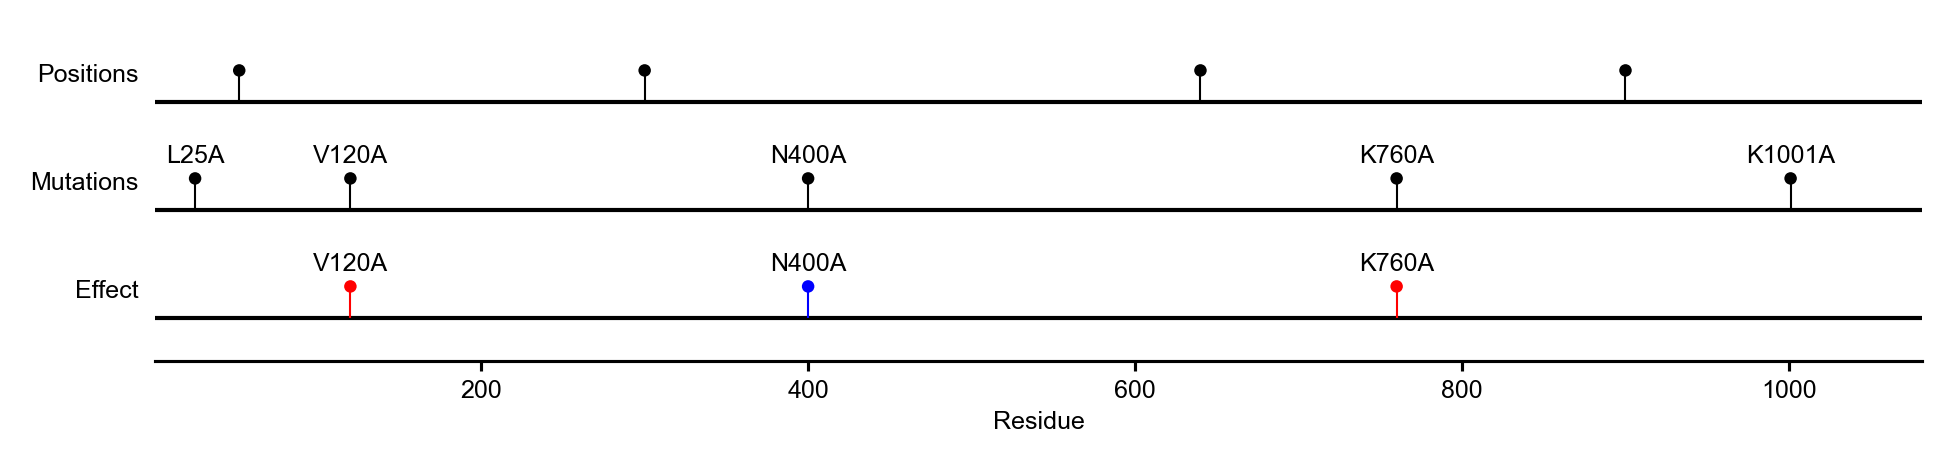

In [11]:
def alanine_mutation(position):
    """The label of a mutation to alanine at a position counting from 1, such as 'Q120A'."""
    return f"{med15_seq[position - 1]}{position}A"


figure, axes = med15.visualize.show_protein(
    sites={
        # just positions
        "Positions": [52, 300, 640, 900],
        # positions and their labels
        "Mutations": {position: alanine_mutation(position) for position in [25, 120, 400, 760, 1001]},
        # Site, for a color: say red for mutations that disrupt something, blue for those that don't
        "Effect": [
            Site(120, alanine_mutation(120), color="red"),
            Site(400, alanine_mutation(400), color="blue"),
            Site(760, alanine_mutation(760), color="red"),
        ],
    },
)

## 8. Domains

Domains go in by the label of their track too, each as any of:

* `(start, end)`;
* `(start, end, label)`;
* a `Domain`, for its color, and where and how its label is written.

Domains in one track can overlap, which is common for things like constructs; overlapping domains are put on as few extra rows as they fit on. The folded domains of Med15 here have the boundaries and colors from Rachel Klevit's 2021 Nat Comms paper, as in [protein_viz_1](protein_viz_1.ipynb).

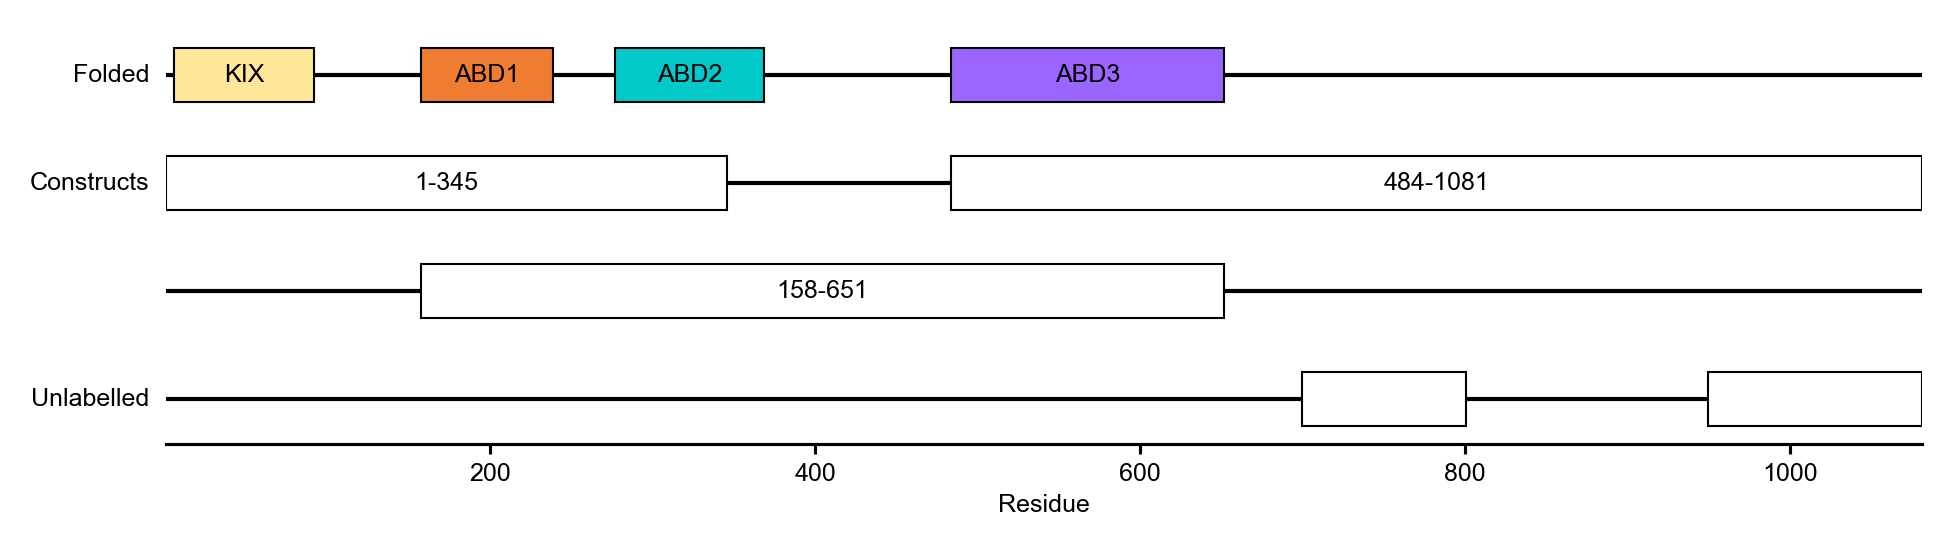

In [12]:
folded = [
    Domain(6, 91, "KIX", color="#ffe699"),
    Domain(158, 238, "ABD1", color="#ee7d31"),
    Domain(277, 368, "ABD2", color="#03c9ca"),
    Domain(484, 651, "ABD3", color="#9a66ff"),
]

figure, axes = med15.visualize.show_protein(
    domains={
        "Folded": folded,
        # these overlap, so they take two rows
        "Constructs": [(1, 345, "1-345"), (158, 651, "158-651"), (484, 1081, "484-1081")],
        "Unlabelled": [(700, 800), (950, 1081)],
    },
)

## 9. Writing the sequence, and shading regions

`sequence` writes the sequence itself: `True` for the whole protein, `'idrs'` for each predicted IDR, or a list of `(start, end)` regions. Each region's sequence is written within its region, in blocks of ten, wrapping onto as many lines as it needs, so the track gets taller for a longer protein or a narrower figure.

`highlights` shades regions behind every track, to guide the eye from one track to the next: `'idrs'` for each predicted IDR, or a list of `(start, end)` regions or `Highlight`, which also takes a color and opacity.

The SARS-CoV-2 N protein is short enough to write out in full.

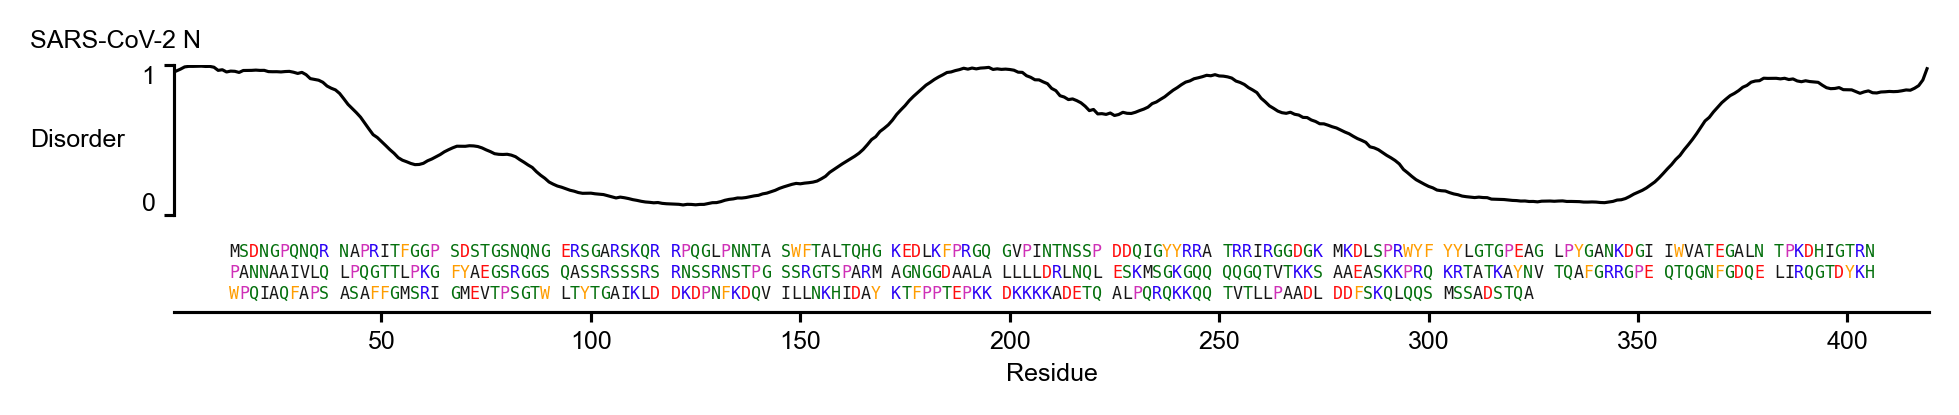

In [13]:
figure, axes = n_protein.visualize.show_protein("predictor.disorder", sequence=True, name="SARS-CoV-2 N")

More often we want the sequence of the IDRs, each within a highlight of the IDR.

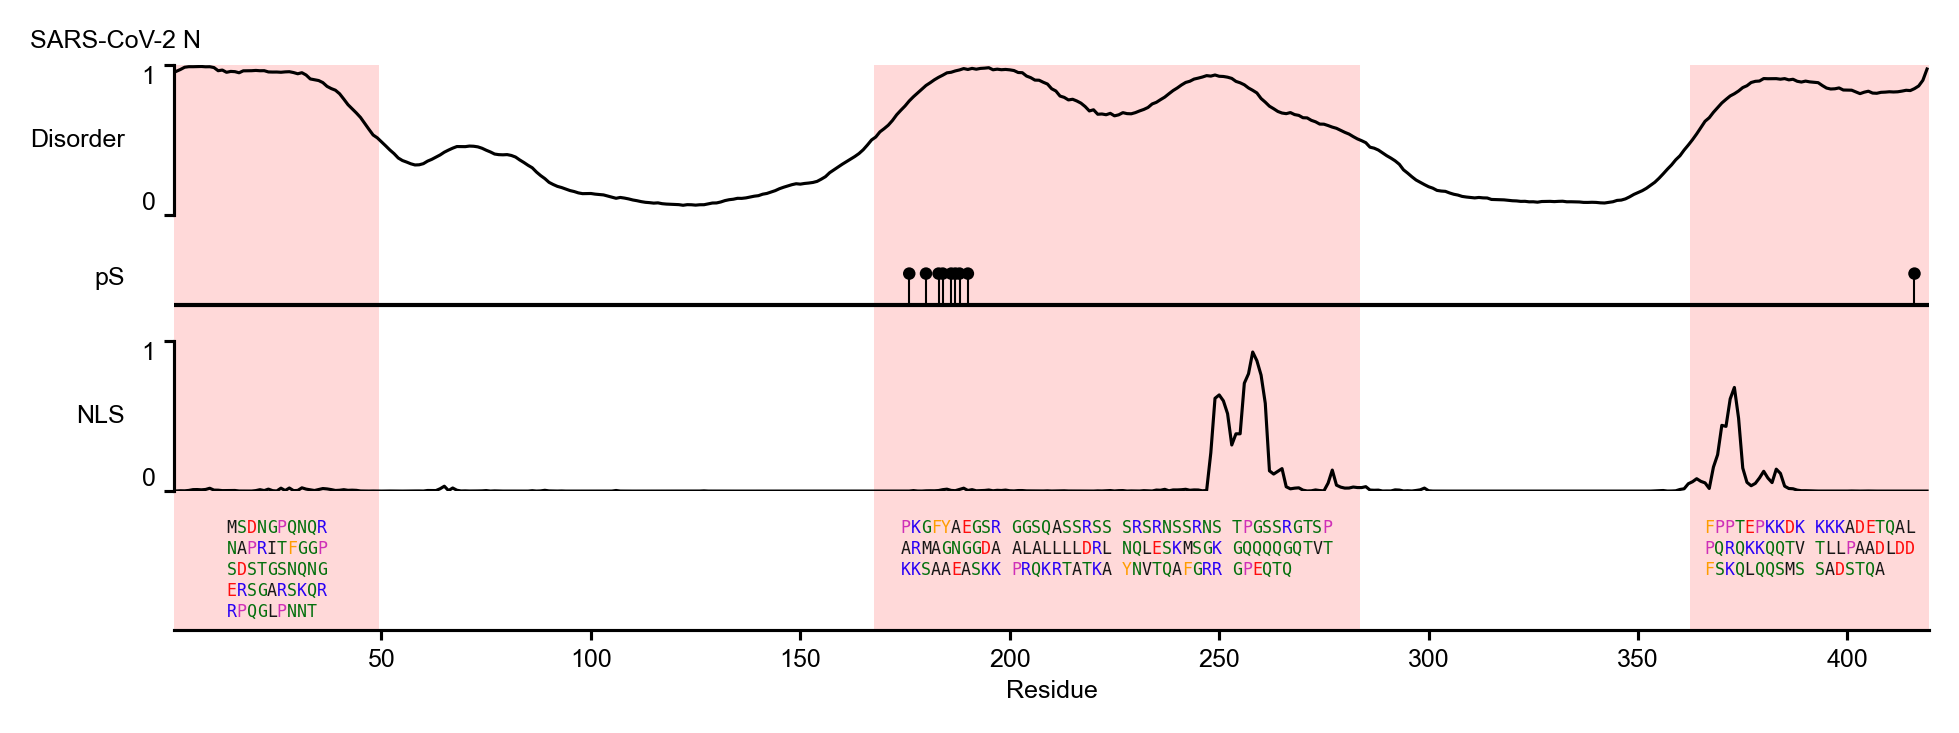

In [14]:
figure, axes = n_protein.visualize.show_protein(
    ["predictor.disorder", "predictor.serine_phosphorylation", "predictor.nuclear_import_signal"],
    sequence="idrs",
    highlights="idrs",
    name="SARS-CoV-2 N",
)

Or regions of our own. The serine-rich stretch of N (176-206) is one of its low-complexity domains, so here we write its sequence, highlight it in red, and highlight the first IDR in blue.

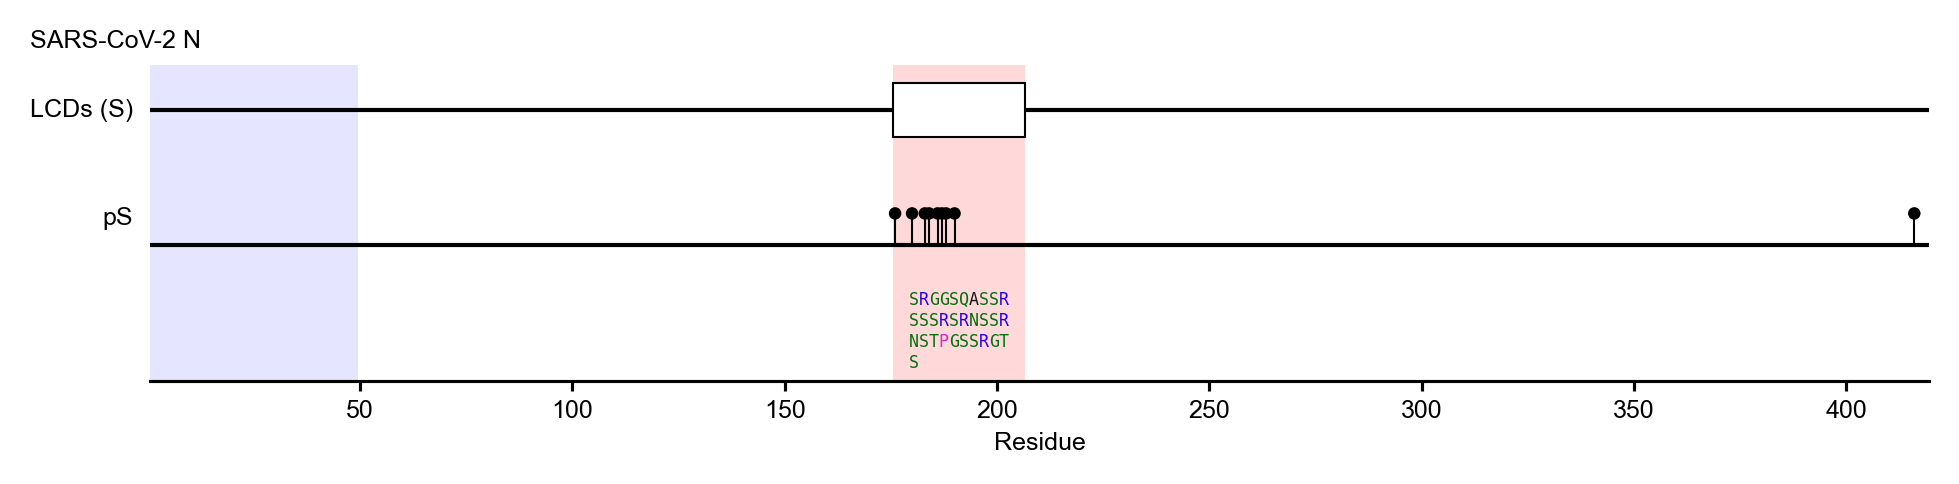

In [15]:
figure, axes = n_protein.visualize.show_protein(
    [{"low_complexity_domains": {"residue_selector": "S"}}, "predictor.serine_phosphorylation"],
    sequence=[(176, 206)],
    highlights=[Highlight(176, 206, color="red"), Highlight(1, 49, color="blue", alpha=0.1)],
    name="SARS-CoV-2 N",
)

## 10. Putting it all together

Everything above can go into one figure. By default the tracks are drawn top to bottom as domains, sites, analyses, signals, tracks of our own, then the sequence.

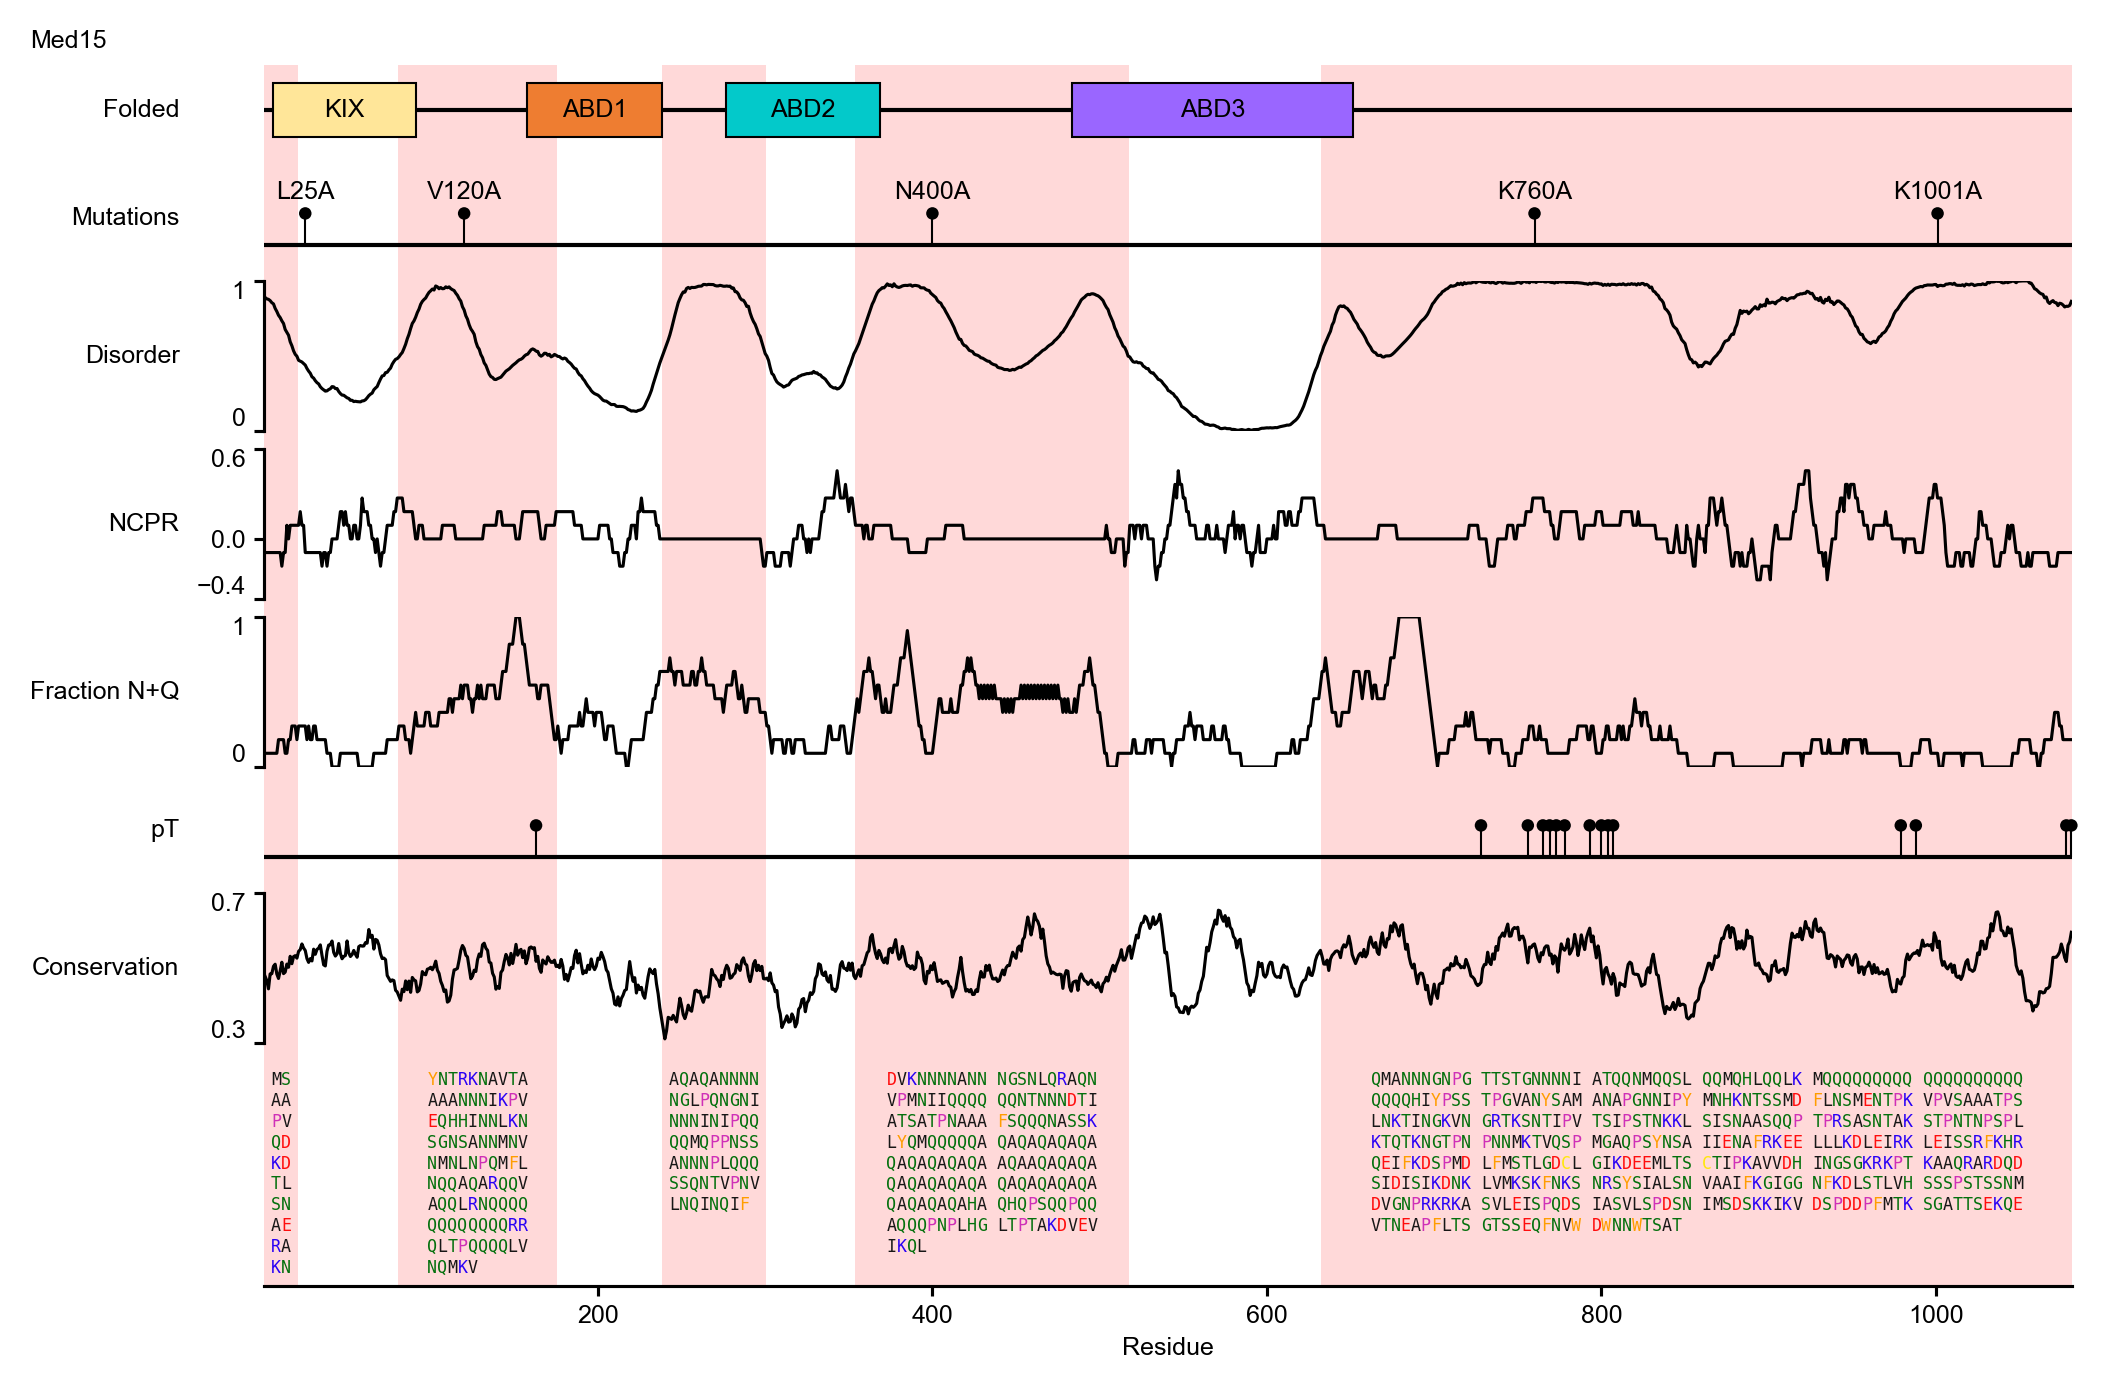

In [16]:
mutations = {position: alanine_mutation(position) for position in [25, 120, 400, 760, 1001]}

figure, axes = med15.visualize.show_protein(
    [
        "predictor.disorder",
        {"linear_sequence_profile": {"mode": "NCPR", "window_size": 11}},
        {"linear_composition_profile": {"composition_list": ["Q", "N"], "window_size": 11}},
        "predictor.threonine_phosphorylation",
    ],
    domains={"Folded": folded},
    sites={"Mutations": mutations},
    signals={"Conservation": conservation},
    sequence="idrs",
    highlights="idrs",
    name="Med15",
    figure_width_in=7,
)

`order` draws the kinds of track in another order. Every kind we've given has to be in it.

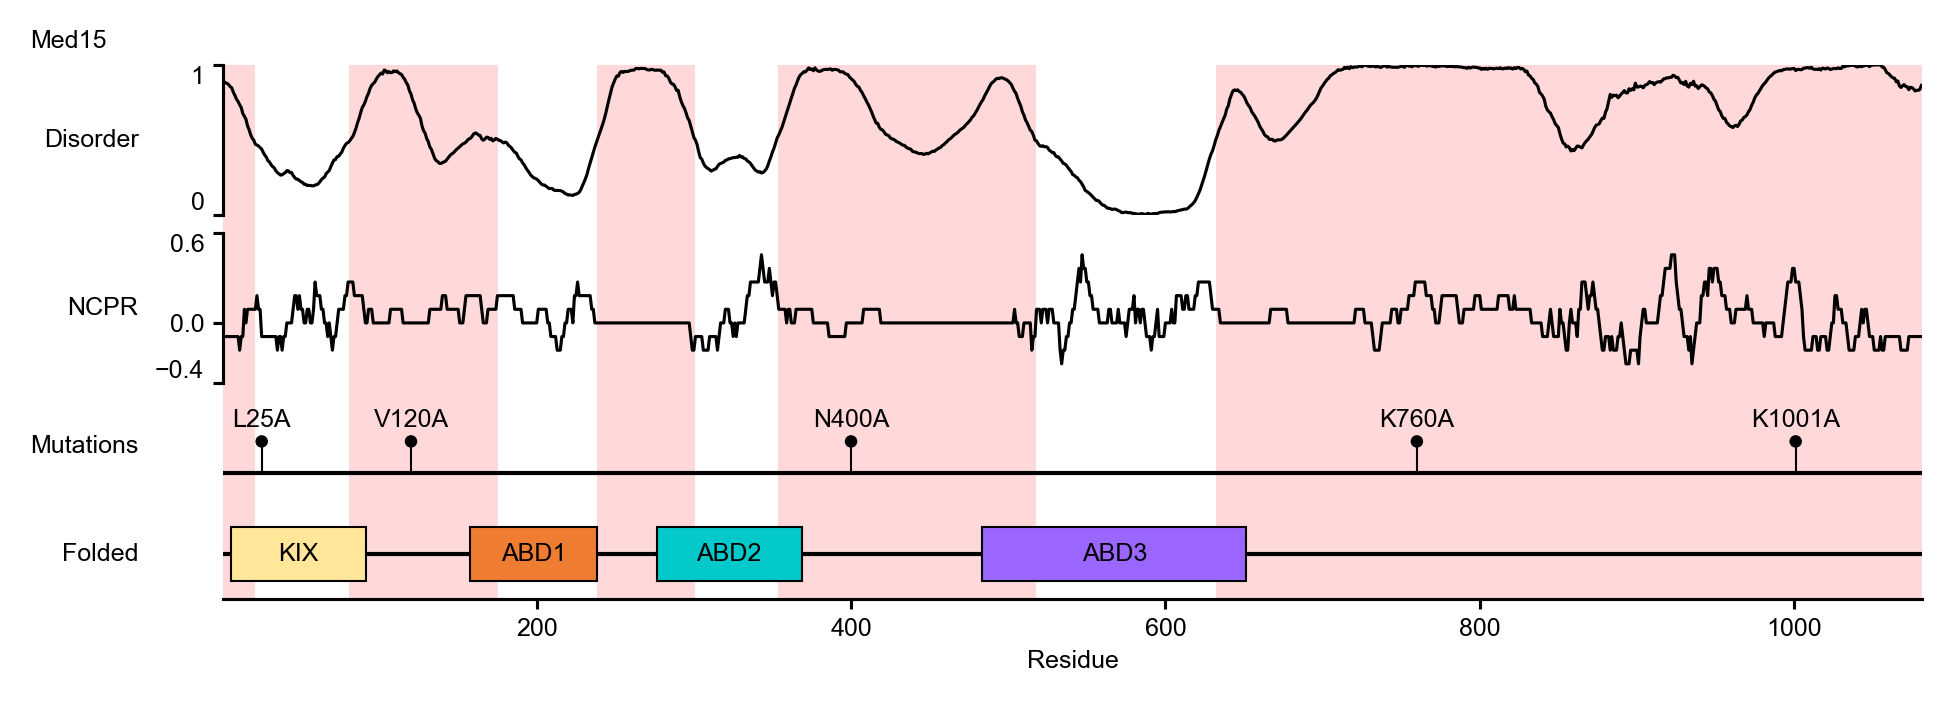

In [17]:
figure, axes = med15.visualize.show_protein(
    ["predictor.disorder", {"linear_sequence_profile": {"mode": "NCPR", "window_size": 11}}],
    domains={"Folded": folded},
    sites={"Mutations": mutations},
    highlights="idrs",
    name="Med15",
    order=("analyses", "sites", "domains"),
)

## 11. Figure size and text

The figure is as wide as `figure_width_in` (in inches), and as tall as its tracks need. `font_size_pt` sets the size of every label. A narrower figure leaves less room across each IDR, so the sequence wraps onto more lines, but it always stays within its IDR.

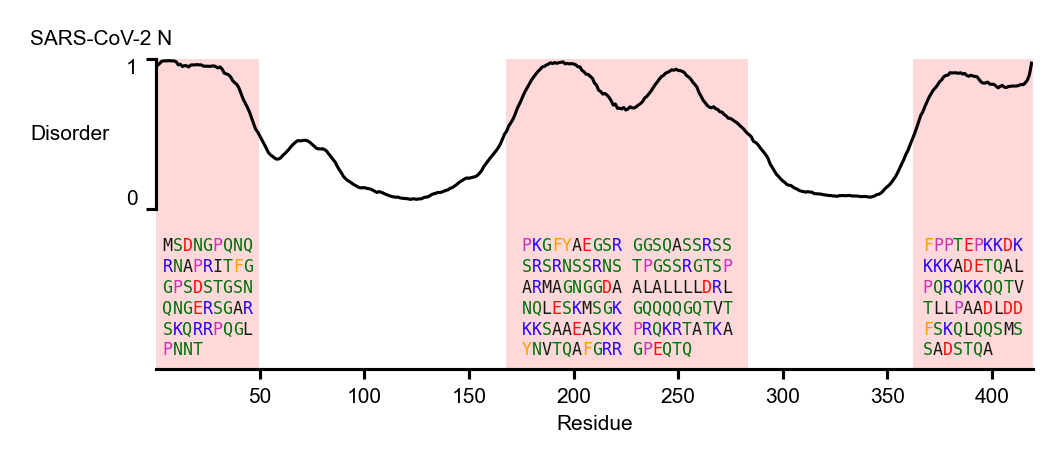

In [18]:
figure, axes = n_protein.visualize.show_protein(
    "predictor.disorder",
    sequence="idrs",
    highlights="idrs",
    name="SARS-CoV-2 N",
    figure_width_in=3.5,
    font_size_pt=5,
)

## 12. Full control with tracks of our own

Every track is drawn in black with sensible limits. For anything else, such as NCPR as bars, a line in color, fixed limits or a heatmap, we make the track ourselves with `sparrow.visualize.proteinvis` and pass it in `tracks`. [protein_viz_1](protein_viz_1.ipynb) and the plotting page of the docs cover every option of every track.

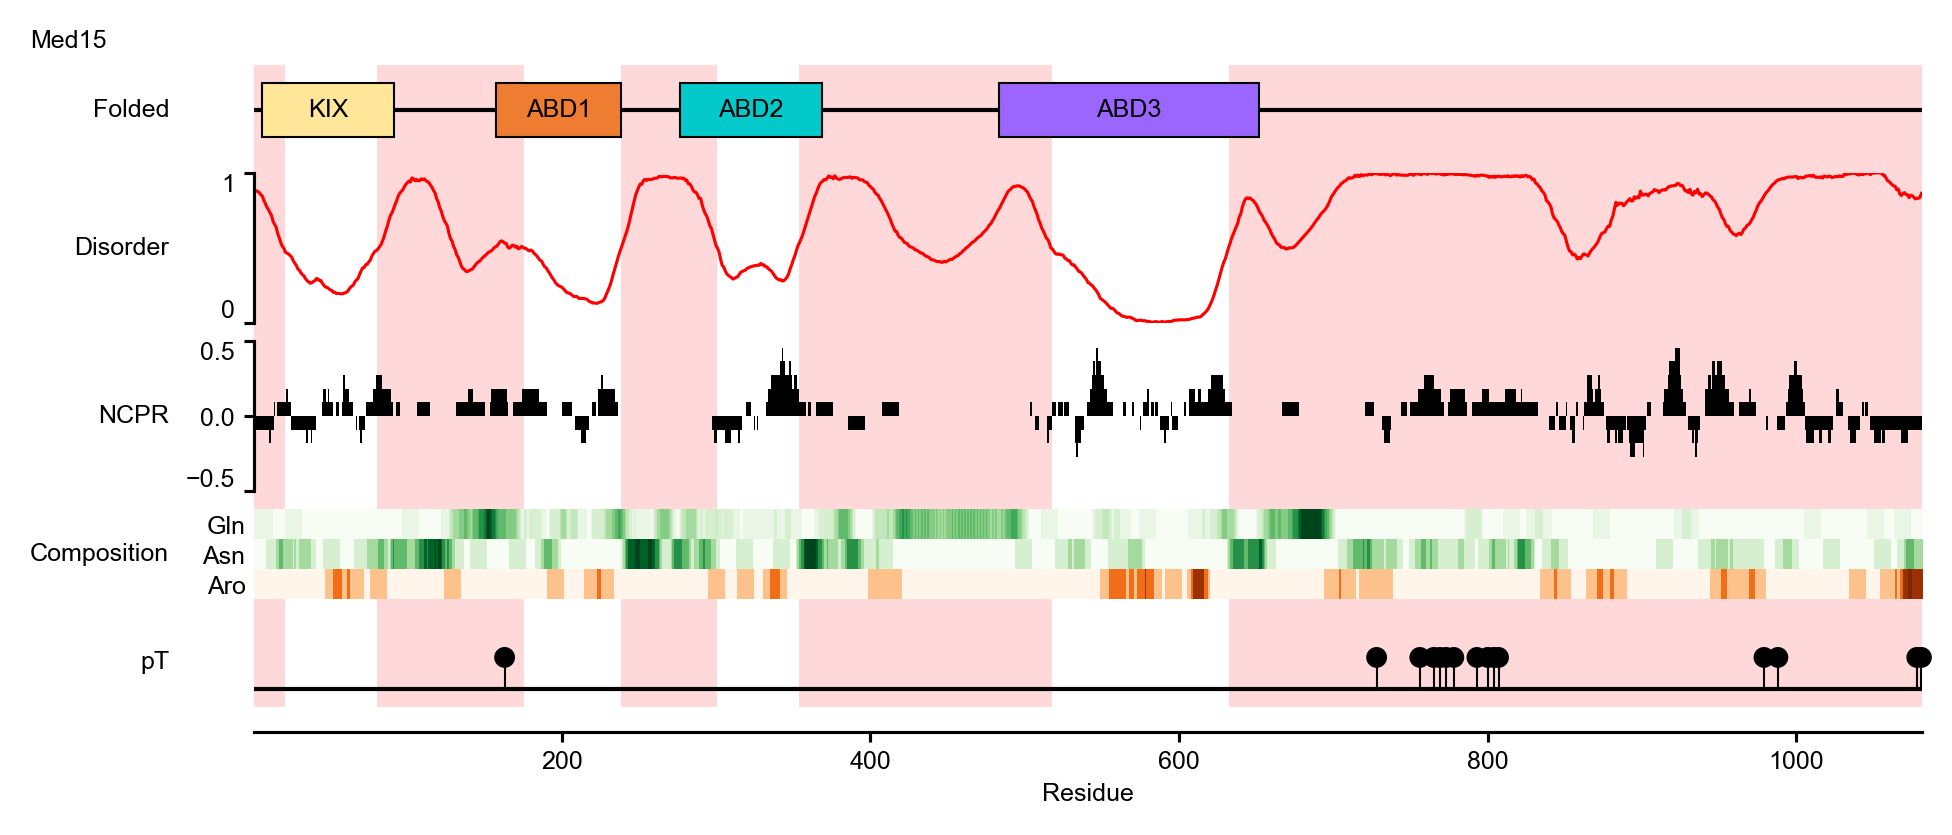

In [19]:
# NCPR as bars, on fixed limits
ncpr_bars = LinearTrack("NCPR", med15.linear_sequence_profile("NCPR", window_size=11), plot_type="bar", y_limits=(-0.5, 0.5))

# disorder in red
red_disorder = LinearTrack("Disorder", med15.predictor.disorder(), color="red", y_limits=(0, 1))

# a heatmap, one row for each profile
composition = GridTrack(
    "Composition",
    [
        med15.linear_composition_profile(["Q"], window_size=11),
        med15.linear_composition_profile(["N"], window_size=11),
        med15.linear_sequence_profile("aromatic", window_size=11),
    ],
    colormaps=["Greens", "Greens", "Oranges"],
    row_names=["Gln", "Asn", "Aro"],
    limits=[(0, 1), (0, 0.5), (0, 0.3)],
)

# sites, with bigger markers than usual
big_sites = SiteTrack("pT", marker_size_pt=5)
for position in np.flatnonzero(med15.predictor.threonine_phosphorylation()) + 1:
    big_sites.add_site(int(position))

figure, axes = med15.visualize.show_protein(
    domains={"Folded": folded},
    tracks=[red_disorder, ncpr_bars, composition, big_sites],
    highlights="idrs",
    name="Med15",
)

## 13. Building without drawing

`visual_protein` takes the same arguments as `show_protein` (apart from the figure's size) but returns the `VisualProtein` rather than drawing it. We can then add tracks or highlights to it, and draw it with `plot_proteins`.

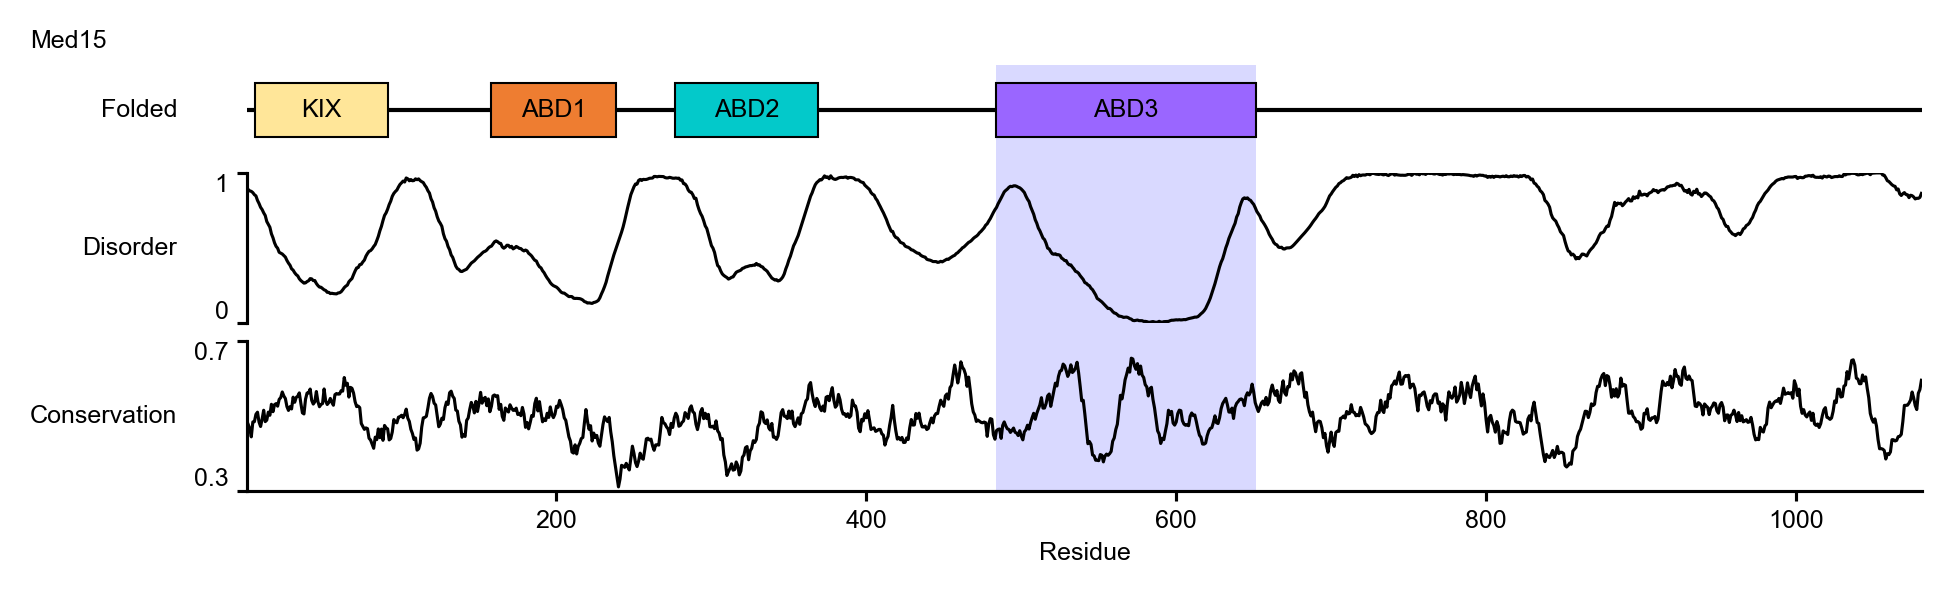

In [20]:
visual = med15.visualize.visual_protein("predictor.disorder", domains={"Folded": folded}, name="Med15")

# add a track and a highlight of our own after the fact
visual.add_track(LinearTrack("Conservation", conservation))
visual.add_highlight(484, 651, color="blue")

figure, axes = plot_proteins(visual)

`plot_proteins` also takes a list, which draws several proteins one above the other on the same residue scale, so a shorter protein ends before the right edge.

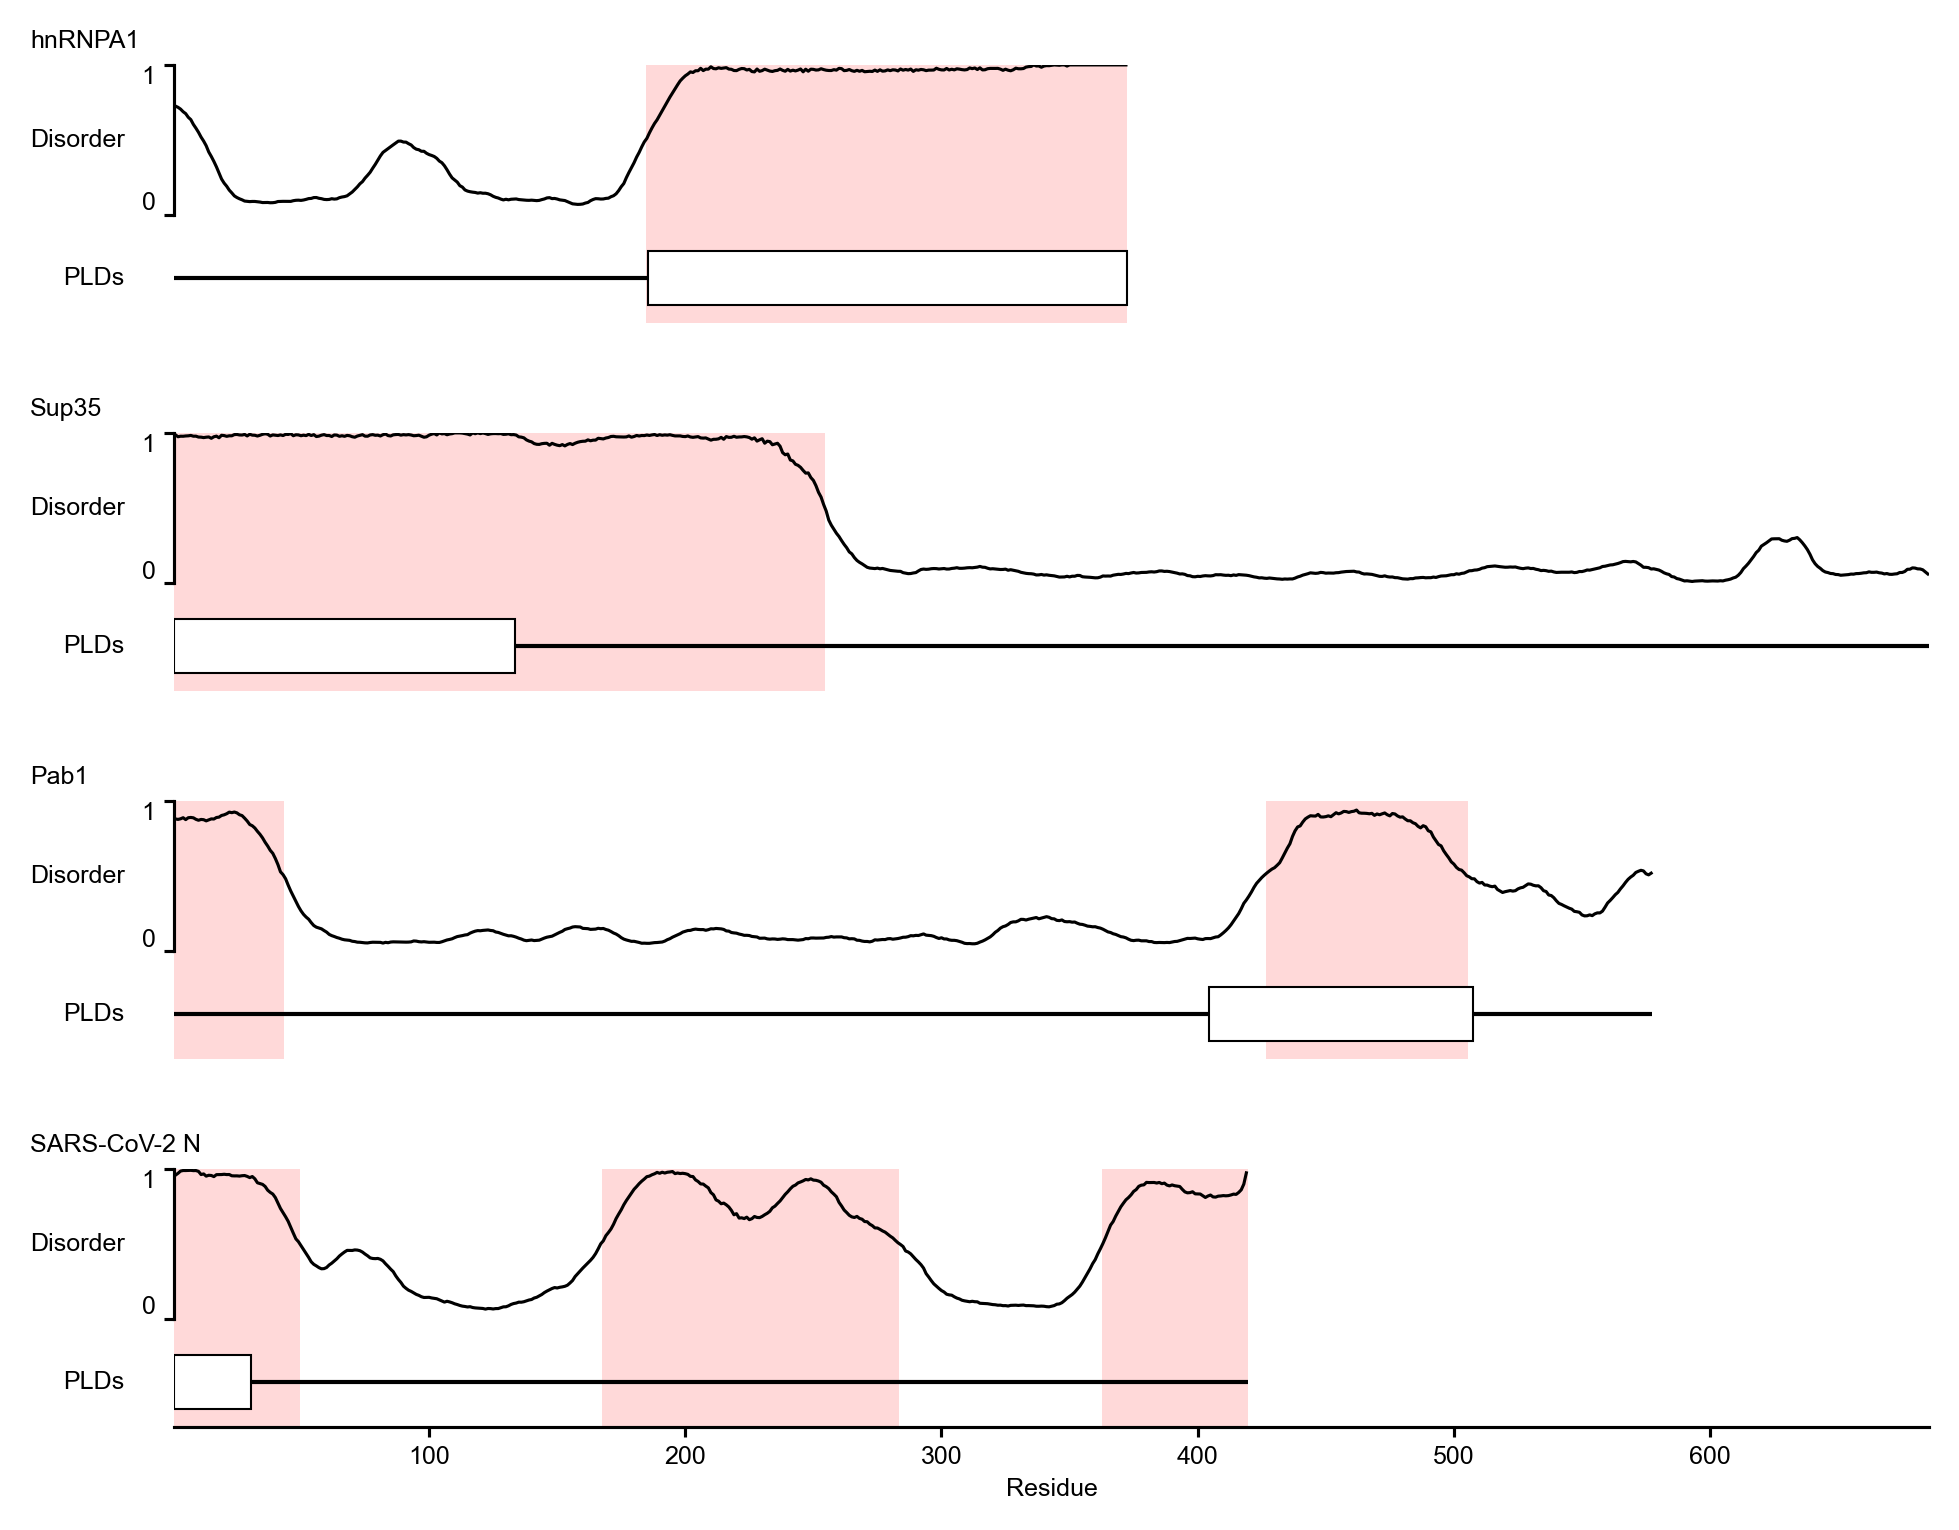

In [21]:
proteins = {"hnRNPA1": hnrnpa1, "Sup35": sup35, "Pab1": pab1, "SARS-CoV-2 N": n_protein}

visuals = [
    protein.visualize.visual_protein(
        ["predictor.disorder", "plaac_prion_like_domains"],
        highlights="idrs",
        name=name,
    )
    for name, protein in proteins.items()
]

figure, axes = plot_proteins(visuals)

## 14. Saving

`save_protein` takes a path and the same arguments as `show_protein`, and draws, saves and closes the figure in one go. The extension sets the format (`.pdf`, `.svg`, `.png` and so on), and the text stays text that Illustrator can edit.

In [22]:
med15.visualize.save_protein(
    "med15_visualize.pdf",
    ["predictor.disorder", {"linear_sequence_profile": {"mode": "NCPR", "window_size": 11}}],
    domains={"Folded": folded},
    sequence="idrs",
    highlights="idrs",
    name="Med15",
)

If we want to change the figure with matplotlib first, we draw it with `show_protein`, change it, and save it with `save_figure` (rather than `figure.savefig`), which keeps the text editable. Here we add a line at 0.5, the threshold metapredict uses to call a residue disordered.

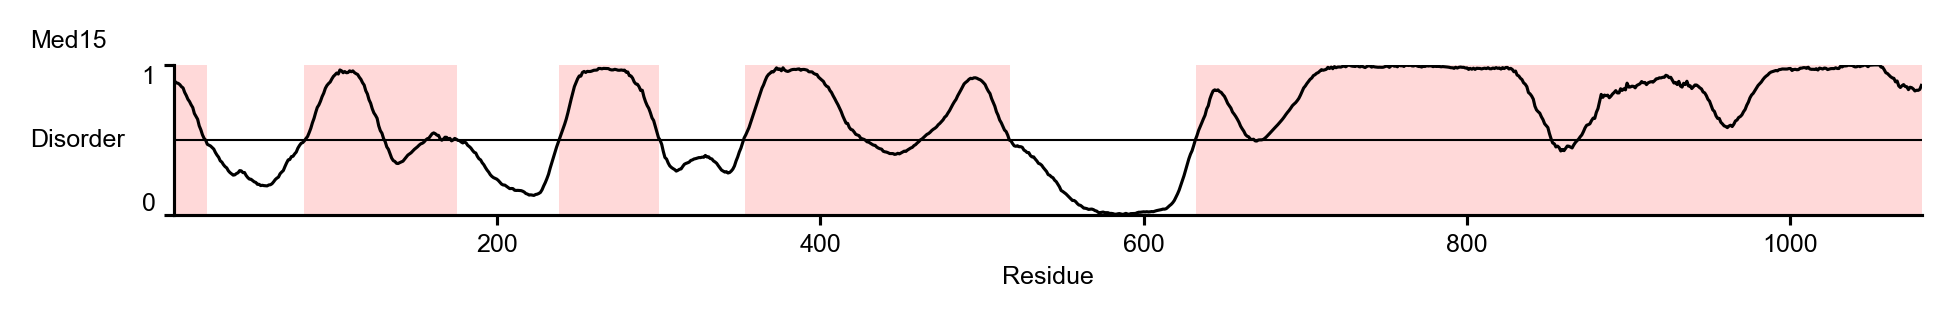

In [23]:
figure, axes = med15.visualize.show_protein("predictor.disorder", highlights="idrs", name="Med15")
axes[0].axhline(0.5, color="black", linewidth=0.5)
save_figure(figure, "med15_disorder.pdf")

## 15. What gets refused

Anything that can't be drawn along the protein is refused, before anything is drawn, with a message saying why: an analysis that gives one number for the whole protein, one that gives the wrong number of values, one that returns something else entirely, a name that isn't an analysis, or an `order` that leaves out something we've given.

In [24]:
attempts = {
    "one number for the whole protein": dict(analyses="FCR"),
    "the wrong number of values": dict(analyses={"linear_sequence_profile": {"mode": "NCPR", "end_mode": ""}}),
    "something else entirely": dict(analyses="elms"),
    "not an analysis": dict(analyses="predictor.not_a_predictor"),
    "an order that leaves out the domains": dict(analyses="predictor.disorder", domains={"Folded": folded}, order=("analyses",)),
}

for what, arguments in attempts.items():
    try:
        med15.visualize.show_protein(**arguments)
    except SparrowException as error:
        print(f"{what}:\n    {error}\n")

one number for the whole protein:
    FCR is one value for the whole protein, so it cannot be drawn along it. ProteinVisualizer.available_analyses() lists those that can.

the wrong number of values:
    linear_sequence_profile with {'mode': 'NCPR', 'end_mode': ''} returns 1074 values for a protein of 1081 residues, so they cannot be drawn one for each residue. For a linear profile, end_mode='extend-ends' gives one for each residue.

something else entirely:
    elms returns a set, not one value for each residue, so it cannot be drawn along the protein. Draw regions of your own with domains=, and sites with sites=.

not an analysis:
    'predictor.not_a_predictor' is not something a Protein computes. Did you mean 'predictor.prefactor' or 'predictor.asphericity' or 'predictor.pscore'? A name is a Protein property or method, such as 'FCR', or one of ['predictor', 'polymeric', 'nardini'] and its method, such as 'predictor.disorder'.

an order that leaves out the domains:
    ['domains'] w